**Import required libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Load the dataset**

In [2]:
df = pd.read_csv("../data/raw/diabetic_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


**Dataset size**

In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 101766
Number of columns: 50


**First 5 rows of the dataset**

In [4]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


**Column names of the dataset**

In [5]:
print(df.columns.tolist())

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


**Check data types**

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

**Check missing values**

In [7]:
missing = df.isnull().sum()

print(missing[missing > 0])

max_glu_serum    96420
A1Cresult        84748
dtype: int64


**Check "?" values**

In [8]:
question_marks = (df == "?").sum()

print(question_marks[question_marks > 0])

#I found that some missing values are represented by a question mark instead of a standard null value. I will 
# handle these missing values during the data-cleaning step rather than changing the original dataset

race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
dtype: int64


**Target variable distribution**

In [9]:
print(df["readmitted"].value_counts())

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


**Target variable distribution in percentage**

In [10]:
print(
    df["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

readmitted
NO     53.91
>30    34.93
<30    11.16
Name: proportion, dtype: float64


**Duplicate encounters**

In [11]:
# Check duplicate records
print(
    "Duplicate encounter IDs:",
    df["encounter_id"].duplicated().sum()
)

Duplicate encounter IDs: 0


**Unique patients**

In [12]:
print(
    "Total patients:",
    df["patient_nbr"].nunique()
)

print(
    "Total encounters:",
    len(df)
)

#Total encounters > Total patients. Because one patient can have multiple hospital encounters.

Total patients: 71518
Total encounters: 101766


**Target visualization**

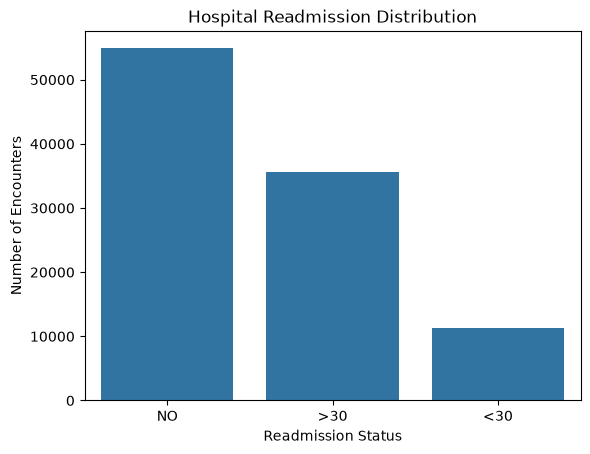

In [13]:
sns.countplot(
    data=df,
    x="readmitted"
)

plt.title("Hospital Readmission Distribution")
plt.xlabel("Readmission Status")
plt.ylabel("Number of Encounters")

plt.show()

## Conclusion

In this notebook, I performed an initial exploration of the Diabetes 130-US Hospitals dataset.

Key findings:
- The dataset contains a large number of hospital encounters and multiple patient-related features.
- The dataset includes demographic, hospital stay, diagnosis, medication, and healthcare utilization information.
- Missing values are present in several columns, including values represented by `?`.
- The target variable, `readmitted`, contains three categories: `NO`, `>30`, and `<30`.
- One patient can have multiple hospital encounters, so patient-level data splitting will be important during machine learning.
- The dataset requires further data cleaning and preprocessing before building machine learning models.

In the next notebook, I will clean the data, handle missing values, and perform exploratory data analysis (EDA) to better understand the factors associated with 30-day hospital readmission.